In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import glob
import numpy as np
from IPython.display import display
import matplotlib.patheffects as pe
from scipy.spatial import KDTree
from mpl_toolkits.mplot3d.art3d import Line3DCollection

In [2]:
geo = pd.read_csv('/mnt/scratch/baburish/doublepulse/gnn/Analysis/geometry_clean.csv')
X = geo['dom_x']
Y = geo['dom_y']
Z = geo['dom_z']

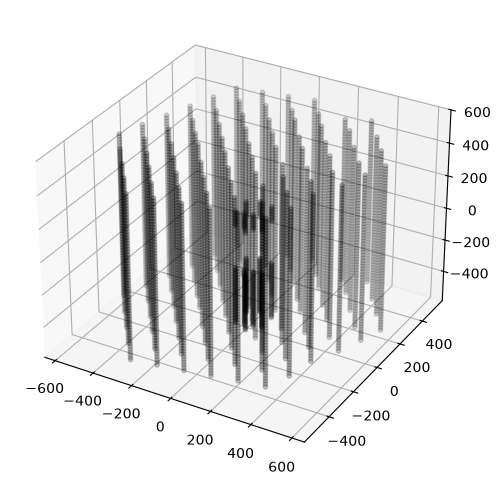

In [3]:
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'projection': '3d'})
ax.scatter(X, Y, Z, s=10, c='k', alpha=0.5)


In [4]:
def map_pulses_to_strings(x, y, z, kd_tree, string_ids_geo, max_distance=50.0):
    """Vectorized string mapping: one batched KDTree query for all hits in
    an event instead of one query per hit."""
    points = np.column_stack([x, y, z])
    distances, idx = kd_tree.query(points, workers=-1)
    strings = string_ids_geo[idx]
    return np.where(distances <= max_distance, strings, -1).astype(int)
def build_geo_dict_kdtree(geo_df):
    """Build KDTree for nearest-neighbor geometry mapping."""
    coords = geo_df[['dom_x', 'dom_y', 'dom_z']].values.astype(float)
    kd_tree = KDTree(coords, leafsize=40)
    string_ids = geo_df['string'].values.astype(int)
    return kd_tree, string_ids

| Truth Table | Pulse Table | Reconstruction Table |
|---|---|---|
| `primary_energy` | `charge` | `run_id` |
| `energy` | `dom_time` | `subrun_id` |
| `position_x` | `dom_x` | `event_id` |
| `position_y` | `dom_y` | `subevent_id` |
| `position_z` | `dom_z` | `brightest_om_brightest_string_id` |
| `azimuth` | `run_id` | `brightest_om_brightest_string_PE` |
| `zenith` | `subrun_id` | `cascade_vertex_fit_x` |
| `pid` | `event_id` | `cascade_vertex_fit_y` |
| `signal` | `subevent_id` | `cascade_vertex_fit_z` |
| `sim_type` | `event_no` | `cascade_reco_energy_tev` |
| `interaction_type` | | `cascade_reco_zenith` |
| `run_id` | | `energy_monopod` |
| `subrun_id` | | `energy_monopod_exists` |
| `event_id` | | `energy_monopod_fit_status` |
| `subevent_id` | | `zenith_monopod` |
| `inelasticity` | | `zenith_monopod_exists` |
| `event_category` | | `mese_filterstream` |
| `seed_string` | | `muonveto` |
| `tau_prod_vertex_x` | | `level5_pass` |
| `tau_prod_vertex_y` | | `cascade_score` |
| `tau_prod_vertex_z` | | `skimming_score` |
| `tau_prod_vertex_t` | | `Starting_Track_classification` |
| `tau_dec_vertex_x` | | `Stopping_Track_classification` |
| `tau_dec_vertex_y` | | `Through_Going_Track_score` |
| `tau_dec_vertex_z` | | `runtime_prediction_score` |
| `tau_dec_vertex_t` | | `runtime_preprocess_score` |
| `e_prod_vertex_x` | | `event_no` |
| `e_prod_vertex_y` | | |
| `e_prod_vertex_z` | | |
| `e_prod_vertex_t` | | |
| `mjd` | | |
| `TIntProbW` | | |
| `OneWeight` | | |
| `Inelasticity_param_a` | | |
| `Inelasticity_param_b` | | |
| `MCPrimaryType` | | |
| `MCPrimaryAzimuth` | | |
| `MCPrimaryEnergy` | | |
| `MCPrimaryZenith` | | |
| `Event` | | |
| `SubEvent` | | |
| `IceScattering` | | |
| `IceAbsorption` | | |
| `DOMEfficiency` | | |
| `IceAnisotropyScale` | | |
| `HoleIceForward_p0` | | |
| `HoleIceForward_p1` | | |
| `MuonWeight` | | |
| `event_no` | | |

In [21]:
db = "/mnt/ufs18/rs/IceCube/lownutau/sqlite/virgo_v4/nue_5TeV_train/nue_5TeV_022856.db"
conn = sqlite3.connect(db)

KEY = ["run_id", "subrun_id", "event_id", "subevent_id"]
Truth_DIR_COLS = ["position_x", "position_y", "position_z", "azimuth", "zenith"]
Reco_DIR_COLS = ['energy_monopod']

n_events = 20

join_conditions = " AND ".join([f"truth.{k} = reco.{k}" for k in KEY])
truth_select = ", ".join([f"truth.{col}" for col in (KEY + Truth_DIR_COLS)])
reco_select = ", ".join([f"reco.{col}" for col in Reco_DIR_COLS])

query = f"""
    SELECT {truth_select}, {reco_select} 
    FROM truth 
    INNER JOIN reco ON {join_conditions}
    ORDER BY truth.rowid 
    LIMIT {n_events}
"""

event_rows = conn.execute(query).fetchall()

events = {}       # event_key -> pulses dataframe
truth_info = {}   # event_key -> dict(position_x, position_y, position_z, azimuth, zenith)
reco_info = {}    # event_key -> dict(energy_monopod)

for row in event_rows:
    key = tuple(row[0:4])
    truth_values = row[4:4 + len(Truth_DIR_COLS)]
    truth_info[key] = dict(zip(Truth_DIR_COLS, truth_values))
    reco_values = row[4 + len(Truth_DIR_COLS):]
    reco_info[key] = dict(zip(Reco_DIR_COLS, reco_values))
    where = " AND ".join(f"{k}={v}" for k, v in zip(KEY, key))
    pulses = conn.execute(f"""
        SELECT dom_x, dom_y, dom_z, charge, dom_time FROM CleanedROIPulses WHERE {where}
    """).fetchall()
    events[key] = pd.DataFrame(pulses, columns=["dom_x", "dom_y", "dom_z", "charge", "dom_time"])
conn.close()

for key, df in events.items():
    print(key, "n_pulse_rows:", len(df), "n_unique_doms:", df[["dom_x","dom_y","dom_z"]].drop_duplicates().shape[0])

(2285600597.0, 4294967295.0, 496.0, 0.0) n_pulse_rows: 460 n_unique_doms: 74
(2285600597.0, 4294967295.0, 522.0, 0.0) n_pulse_rows: 5 n_unique_doms: 2
(2285600597.0, 4294967295.0, 750.0, 0.0) n_pulse_rows: 495 n_unique_doms: 76
(2285600597.0, 4294967295.0, 764.0, 0.0) n_pulse_rows: 532 n_unique_doms: 48
(2285600597.0, 4294967295.0, 839.0, 0.0) n_pulse_rows: 2624 n_unique_doms: 216
(2285600597.0, 4294967295.0, 865.0, 0.0) n_pulse_rows: 445 n_unique_doms: 68
(2285600597.0, 4294967295.0, 894.0, 0.0) n_pulse_rows: 1106 n_unique_doms: 139
(2285600597.0, 4294967295.0, 899.0, 0.0) n_pulse_rows: 873 n_unique_doms: 125
(2285600597.0, 4294967295.0, 1048.0, 0.0) n_pulse_rows: 1849 n_unique_doms: 131
(2285600597.0, 4294967295.0, 1081.0, 0.0) n_pulse_rows: 1799 n_unique_doms: 125
(2285600597.0, 4294967295.0, 1344.0, 0.0) n_pulse_rows: 1920 n_unique_doms: 168
(2285600597.0, 4294967295.0, 1407.0, 0.0) n_pulse_rows: 498 n_unique_doms: 57
(2285600597.0, 4294967295.0, 1492.0, 0.0) n_pulse_rows: 1041 n_u

/tmp/ipykernel_752294/2719283322.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_752294/2719283322.py:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


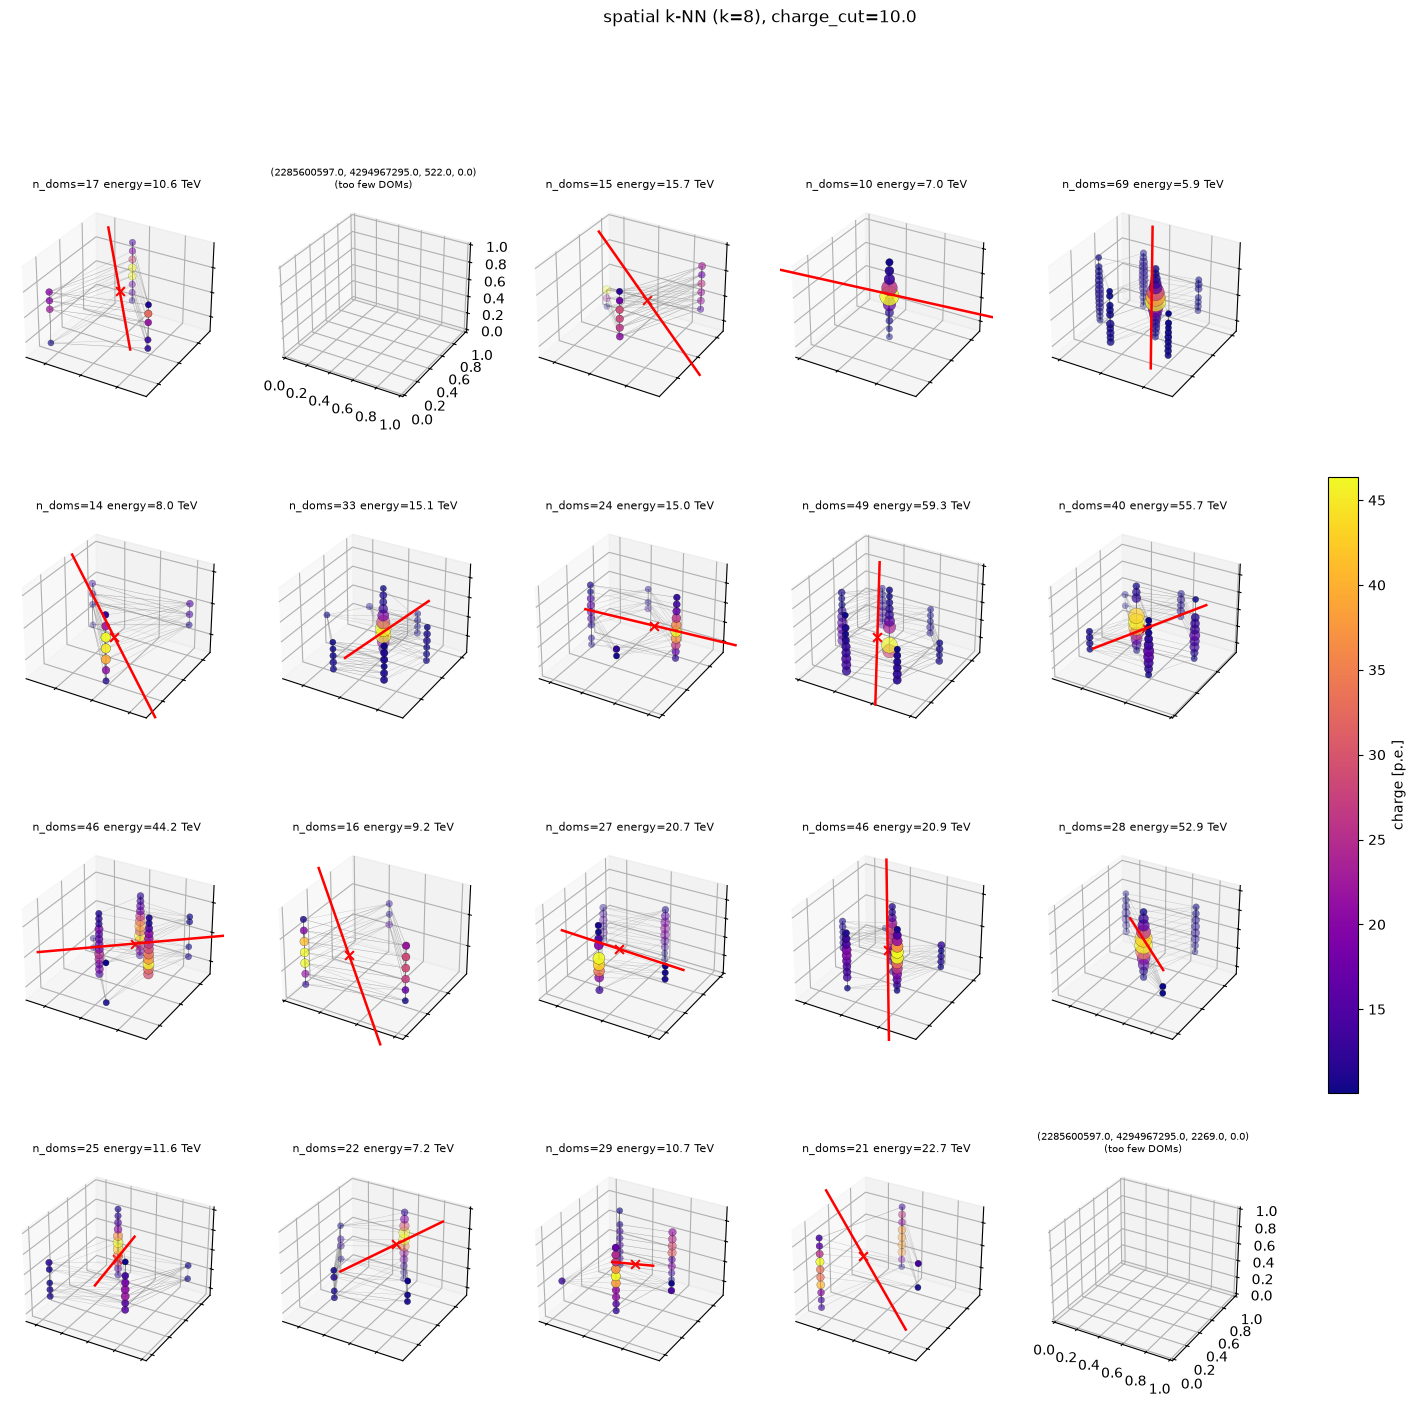

In [29]:
charge_cut = 10.0
k = 8

def direction_vector(azimuth, zenith):
    dx = -np.sin(zenith) * np.cos(azimuth)
    dy = -np.sin(zenith) * np.sin(azimuth)
    dz = -np.cos(zenith)
    return np.array([dx, dy, dz])

def plot_knn_graph(ax, dom_pos, dom_charge, knn_idx, direction, title):
    segments = [[dom_pos[i], dom_pos[j]] for i in range(len(dom_pos)) for j in knn_idx[i]]
    lc = Line3DCollection(segments, colors="gray", linewidths=0.3, alpha=0.4)
    ax.add_collection3d(lc)

    im = ax.scatter(
        dom_pos[:, 0], dom_pos[:, 1], dom_pos[:, 2],
        s=np.sqrt(dom_charge * 20) + 5,
        c=dom_charge, cmap="plasma",
        edgecolors="k", linewidths=0.2, depthshade=True,
    )

    # anchor the direction line at the charge-weighted centroid of the hits,
    # not at the true vertex -- the vertex can sit well outside the cluster
    mins, maxs = dom_pos.min(axis=0), dom_pos.max(axis=0)
    extent = np.linalg.norm(maxs - mins)
    centroid = np.average(dom_pos, axis=0, weights=dom_charge)

    half_len = extent * 0.6
    p0 = centroid - direction * half_len
    p1 = centroid + direction * half_len
    ax.plot(*zip(p0, p1), color="red", linewidth=1.8, zorder=9)
    ax.scatter(*centroid, color="red", marker="x", s=40, zorder=10)

    pad = extent * 0.1
    ax.set_xlim(mins[0] - pad, maxs[0] + pad)
    ax.set_ylim(mins[1] - pad, maxs[1] + pad)
    ax.set_zlim(mins[2] - pad, maxs[2] + pad)

    ax.set_title(title, fontsize=8)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    return im

n_events = len(events)
ncols = 5
nrows = int(np.ceil(n_events / ncols))
fig = plt.figure(figsize=(4 * ncols, 4 * nrows))

im = None
for i, (ekey, df) in enumerate(events.items()):
    agg = df.groupby(["dom_x", "dom_y", "dom_z"], as_index=False)["charge"].sum()
    dom_pos    = agg[["dom_x", "dom_y", "dom_z"]].values
    dom_charge = agg["charge"].values

    keep = dom_charge >= charge_cut
    dom_pos, dom_charge = dom_pos[keep], dom_charge[keep]
    n_doms = len(dom_pos)

    ax = fig.add_subplot(nrows, ncols, i + 1, projection="3d")

    info = truth_info[ekey]
    energy = reco_info[ekey]["energy_monopod"]
    direction = direction_vector(info["azimuth"], info["zenith"])

    if n_doms < 2:
        ax.set_title(f"{ekey}\n(too few DOMs)", fontsize=7)
        continue

    tree = KDTree(dom_pos)
    k_eff = min(k, n_doms - 1)
    _, knn_idx = tree.query(dom_pos, k=k_eff + 1)
    knn_idx = knn_idx[:, 1:]

    im = plot_knn_graph(ax, dom_pos, dom_charge, knn_idx, direction, f"n_doms={n_doms} energy={energy/1e3:.1f} TeV")

if im is not None:
    cbar = fig.colorbar(im, ax=fig.get_axes(), shrink=0.5, pad=0.05)
    cbar.set_label("charge [p.e.]")

plt.suptitle(f"spatial k-NN (k={k}), charge_cut={charge_cut}")
plt.tight_layout()
plt.show()

event (2285600597.0, 4294967295.0, 1808.0, 0.0): 22 DOMs kept after charge cut


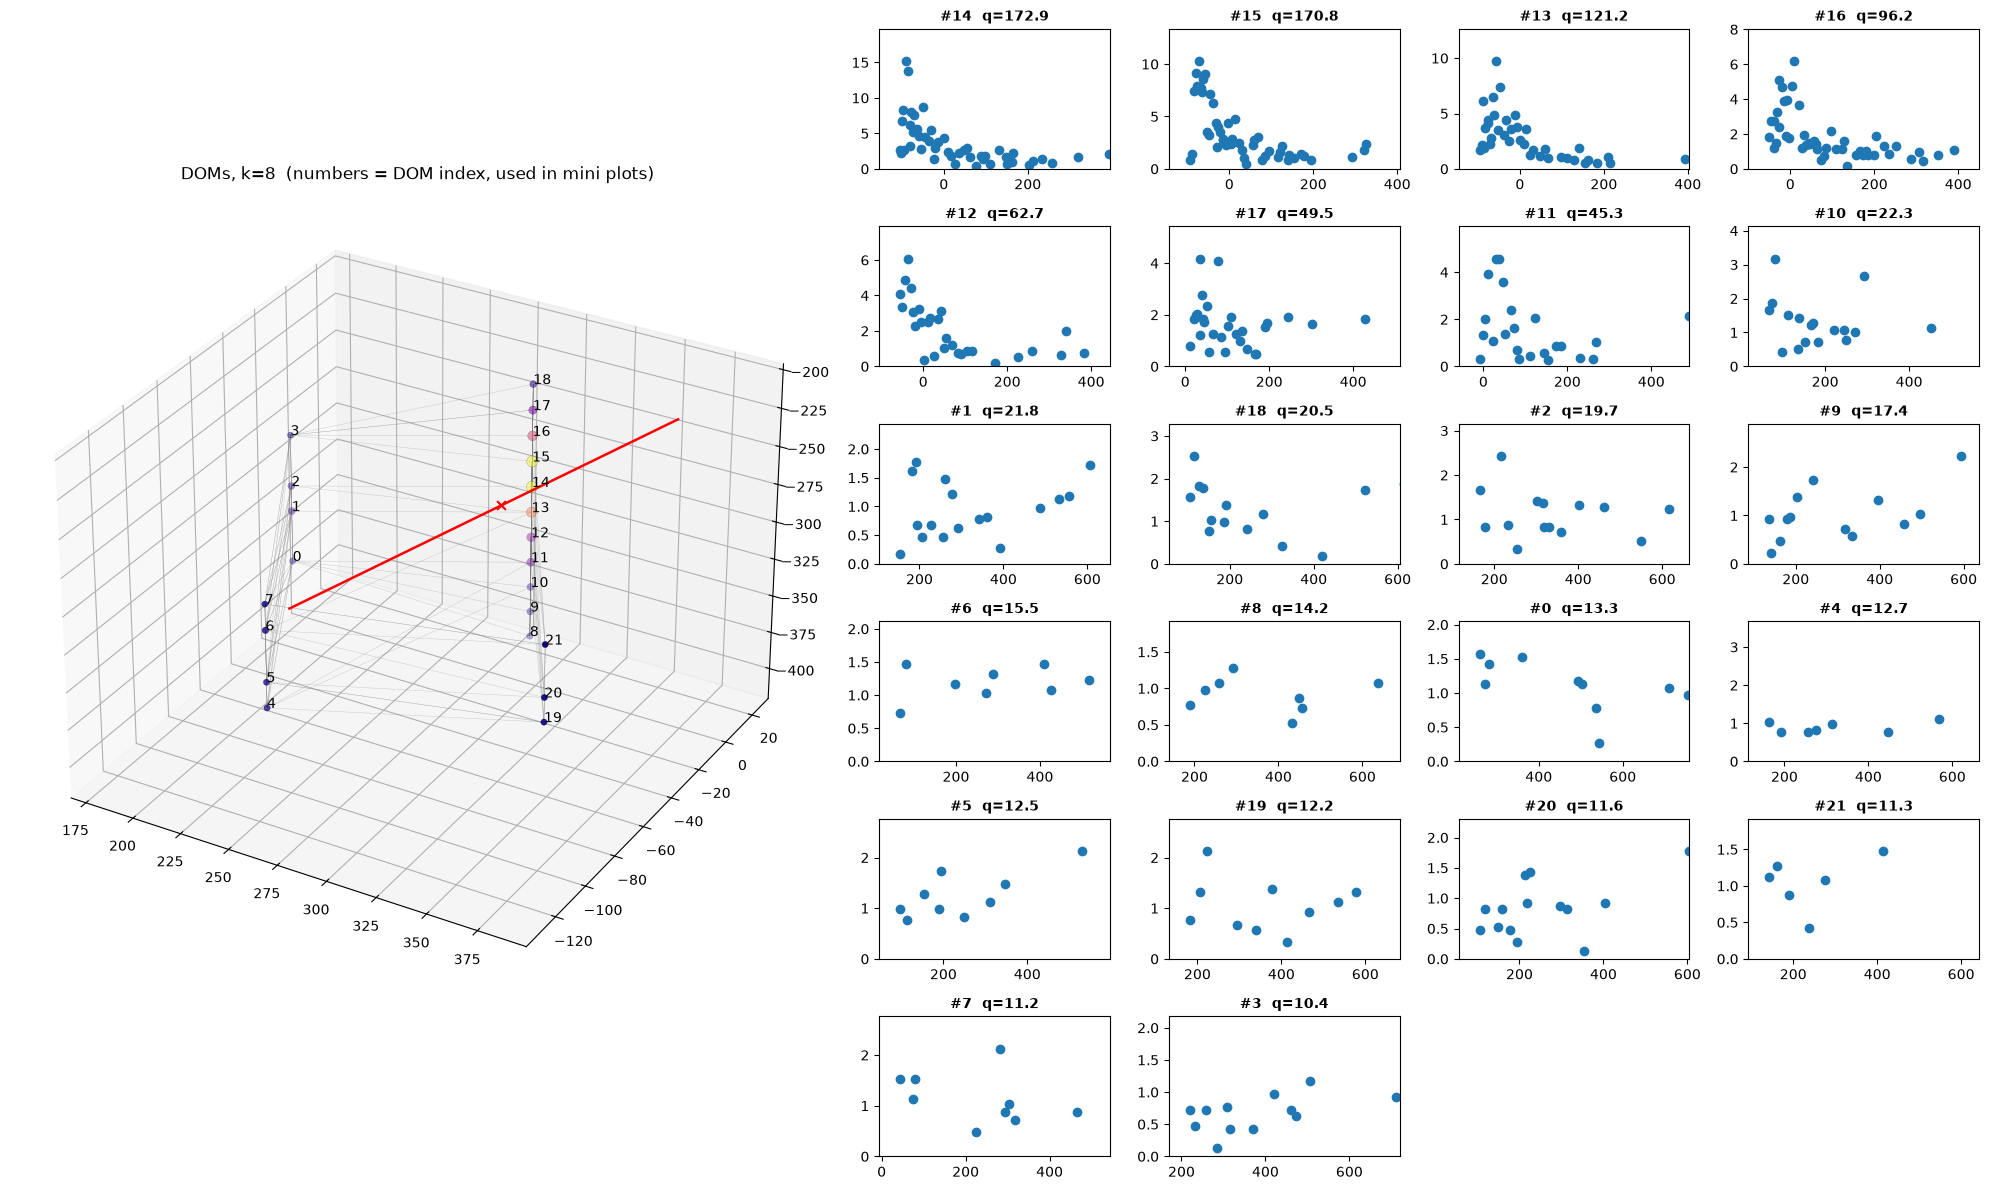

In [28]:
event_idx = 16

def direction_vector(azimuth, zenith):
    dx = -np.sin(zenith) * np.cos(azimuth)
    dy = -np.sin(zenith) * np.sin(azimuth)
    dz = -np.cos(zenith)
    return np.array([dx, dy, dz])

ekey = list(events.keys())[event_idx]
df = events[ekey]

agg = df.groupby(["dom_x", "dom_y", "dom_z"], as_index=False)["charge"].sum()
dom_pos_full    = agg[["dom_x", "dom_y", "dom_z"]].values
dom_charge_full = agg["charge"].values

keep = dom_charge_full >= charge_cut
dom_pos    = dom_pos_full[keep]
dom_charge = dom_charge_full[keep]
n_doms = len(dom_pos)
print(f"event {ekey}: {n_doms} DOMs kept after charge cut")

tree = KDTree(dom_pos)
k_eff = min(k, n_doms - 1)
_, knn_idx = tree.query(dom_pos, k=k_eff + 1)
knn_idx = knn_idx[:, 1:]

info = truth_info[ekey]
direction = direction_vector(info["azimuth"], info["zenith"])

dom_order = np.argsort(-dom_charge)  # indices into dom_pos, brightest first
dom_hits = []
for rank, i in enumerate(dom_order):
    dx, dy, dz = dom_pos[i]
    sel = df[(df.dom_x == dx) & (df.dom_y == dy) & (df.dom_z == dz)].sort_values("dom_time")
    dom_hits.append((i, dom_charge[i], dx, dy, dz, sel["dom_time"].values, sel["charge"].values))

n_small = len(dom_hits)
ncols_small = 4
nrows_small = int(np.ceil(n_small / ncols_small))

fig = plt.figure(figsize=(8 + 3 * ncols_small, max(6, 2 * nrows_small)))
gs = fig.add_gridspec(nrows_small, ncols_small + 3)

ax3d = fig.add_subplot(gs[:, :3], projection="3d")
segments = [[dom_pos[a], dom_pos[b]] for a in range(n_doms) for b in knn_idx[a]]
lc = Line3DCollection(segments, colors="gray", linewidths=0.3, alpha=0.4)
ax3d.add_collection3d(lc)
im = ax3d.scatter(
    dom_pos[:, 0], dom_pos[:, 1], dom_pos[:, 2],
    s=np.sqrt(dom_charge * 20) + 5,
    c=dom_charge, cmap="plasma",
    edgecolors="k", linewidths=0.2, depthshade=True,
)
for i in range(n_doms):
    ax3d.text(dom_pos[i, 0], dom_pos[i, 1], dom_pos[i, 2], str(i),
              fontsize=10, color="black", zorder=11)

mins, maxs = dom_pos.min(axis=0), dom_pos.max(axis=0)
extent = np.linalg.norm(maxs - mins)
centroid = np.average(dom_pos, axis=0, weights=dom_charge)
half_len = extent * 0.6
p0, p1 = centroid - direction * half_len, centroid + direction * half_len
ax3d.plot(*zip(p0, p1), color="red", linewidth=1.8, zorder=9)
ax3d.scatter(*centroid, color="red", marker="x", s=40, zorder=10)
pad = extent * 0.1
ax3d.set_xlim(mins[0]-pad, maxs[0]+pad); ax3d.set_ylim(mins[1]-pad, maxs[1]+pad); ax3d.set_zlim(mins[2]-pad, maxs[2]+pad)
ax3d.set_title(f" DOMs, k={k}  (numbers = DOM index, used in mini plots)")
# fig.colorbar(im, ax=ax3d, shrink=0.5, pad=0.1).set_label("charge [p.e.]")

for rank, (i, q_tot, dx, dy, dz, t_vals, q_vals) in enumerate(dom_hits):
    r, c = divmod(rank, ncols_small)
    ax = fig.add_subplot(gs[r, 3 + c])
    ax.scatter(t_vals, q_vals)#, basefmt=" ")
    ax.set_title(f"#{i}  q={q_tot:.1f}", fontsize=10, fontweight="bold")
    ax.tick_params(labelsize=10)
    ax.set_xlim(t_vals.min()-50, t_vals.min()+500)
    ax.set_ylim(0, q_vals.max()*1.3)

plt.tight_layout()
plt.show()